<a href="https://colab.research.google.com/github/Rosary-mom/Bio2.0/blob/main/k3/ESG_Cockpit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ESG-Cockpit · EKIR / EAIR
**Emergente KI-Revolution** — Entscheidungs-Cockpit zur Essay-Fassung v2  
*Uwe Rosenkranz · Forschungsfassung 2. Nov. 2026 · Bio 2.0 / Rosary*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rosary-mom/Bio2.0/blob/main/k3/ESG_Cockpit.ipynb)

### So startest du (Colab Free / T4)
1. Oben auf **Laufzeit → Laufzeittyp ändern → T4-GPU** (Hardwarebeschleuniger).
2. Dann **Laufzeit → Alle ausführen** (von oben nach unten).
3. Das Cockpit läuft auch **ohne** LLM-Assistenten vollständig. Die LLM-Zelle lädt optional **Qwen2.5-7B-Instruct** (4-Bit) bzw. fällt auf **Qwen2.5-1.5B-Instruct** zurück — Apache-2.0, ohne API-Key.
4. Schalter **„RKW-Cockpit (schlafend) zuschalten“** ist standardmäßig **aus**.

**Leitsatz:** *Verstehen schlägt bloße Größe.* Alle Zahlen tragen Provenienz. Nichts wird erfunden.

## Abhängigkeiten installieren (Colab)

In [29]:
# Abhängigkeiten (Colab / lokal) — einmal ausführen
import sys, subprocess

def _pip(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

need = []
for mod, pkg in [
    ("ipywidgets", "ipywidgets"),
    ("transformers", "transformers"),
    ("accelerate", "accelerate"),
    ("bitsandbytes", "bitsandbytes"),
]:
    try:
        __import__(mod)
    except Exception:
        need.append(pkg)

for mod, pkg in [("pandas", "pandas"), ("matplotlib", "matplotlib"), ("PIL", "Pillow")]:
    try:
        __import__(mod)
    except Exception:
        need.append(pkg)

if need:
    print("Installiere:", ", ".join(need))
    _pip(*need)
else:
    print("Abhängigkeiten bereits vorhanden.")

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except Exception:
    IN_COLAB = False
print("IN_COLAB =", IN_COLAB)


Abhängigkeiten bereits vorhanden.
IN_COLAB = True


## 0 · Setup, Seeds, Headless-Modus

In [30]:
import os, json, math, hashlib, warnings, re
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except Exception:
    IN_COLAB = False

# Headless nur bei explizitem Flag (nbconvert/CI) — Colab nie headless

# GPU-Hinweis früh (Colab ohne T4 → ungenaues kleines Modell)
try:
    import torch as _t0
    _has_cuda = _t0.cuda.is_available()
except Exception:
    _has_cuda = False
if not _has_cuda:
    _w = "Keine GPU! Laufzeit → Laufzeittyp ändern → T4-GPU, speichern, dann Alle ausführen. Sonst nur kleines Modell, ungenauer."
    try:
        from IPython.display import display, Markdown
        display(Markdown(f"> **⚠️ {_w}**"))
    except Exception:
        print("⚠️", _w)

HEADLESS = os.environ.get("COCKPIT_HEADLESS", "").strip().lower() in {"1", "true", "yes"}
if IN_COLAB:
    HEADLESS = False

SKIP_LLM = os.environ.get("SKIP_LLM", "0").strip().lower() in {"1", "true", "yes"}
if HEADLESS and "SKIP_LLM" not in os.environ:
    SKIP_LLM = True

if HEADLESS:
    matplotlib.use("Agg")

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)

try:
    import ipywidgets as widgets
    from IPython.display import display, Markdown, clear_output, HTML
    HAS_WIDGETS = True
except Exception:
    HAS_WIDGETS = False
    class _Dummy:
        def __init__(self, **kw):
            self.__dict__.update(kw)
            self.value = kw.get("value", False)
        def observe(self, *a, **k): pass
        def on_click(self, *a, **k): pass
    class widgets:  # type: ignore
        Checkbox = ToggleButton = FloatSlider = Dropdown = Text = Button = Output = VBox = HBox = HTML = Label = Accordion = _Dummy
        Layout = lambda **kw: None
    def display(*a, **k):
        for x in a:
            if isinstance(x, (pd.DataFrame, pd.Series)):
                print(x.to_string())
            else:
                print(x)
    def Markdown(s): return s
    def clear_output(*a, **k): pass
    def HTML(s): return s

if os.environ.get("COCKPIT_OUT"):
    OUT_DIR = Path(os.environ["COCKPIT_OUT"])
elif IN_COLAB:
    OUT_DIR = Path("/content/esg_cockpit_out")
else:
    OUT_DIR = Path("cockpit_out")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"SEED={SEED} | IN_COLAB={IN_COLAB} | HEADLESS={HEADLESS} | SKIP_LLM={SKIP_LLM} | widgets={HAS_WIDGETS}")
print(f"OUT_DIR={OUT_DIR.resolve()}")


SEED=42 | IN_COLAB=True | HEADLESS=False | SKIP_LLM=False | widgets=True
OUT_DIR=/content/esg_cockpit_out


## 1 · Evidenzleiter & Klassifikation
Stufen zunehmender Prüfbarkeit (Schema der Essay-Fassung; **keine** empirische Skala).
Jede Aussage im Cockpit trägt eine dieser Klassen plus Provenienz.

,Klasse,Bezeichnung,Regel
0,measured,Messwert / Assay,Feld-/Labormessung mit Protokoll
1,derived,Abgeleitet / transkribiert,aus Messungen oder Tabellen berechnet/abgelesen
2,simulation,Simulation / Sensitivität,"Modellkurve, Szenario, Seed"
3,governance_telemetry,Governance-Telemetrie,operational definierte Kennzahl (Modul 04)
4,author_claim,Autoren-Claim + Provenienz,Claim-Klasse mit dokumentierter Herkunft; nich...
5,exact_formal,Exakt / formal,mathematisches Zertifikat (z. B. Graffiti 284)


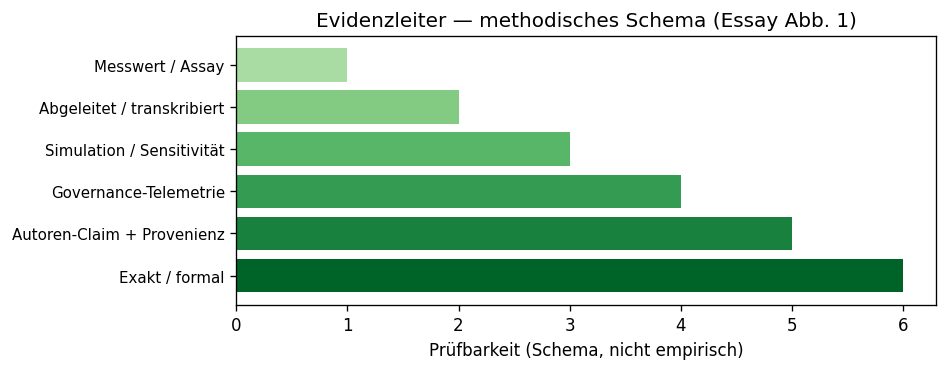

In [31]:
EVIDENZKLASSEN = [
    ("measured", "Messwert / Assay", "Feld-/Labormessung mit Protokoll"),
    ("derived", "Abgeleitet / transkribiert", "aus Messungen oder Tabellen berechnet/abgelesen"),
    ("simulation", "Simulation / Sensitivität", "Modellkurve, Szenario, Seed"),
    ("governance_telemetry", "Governance-Telemetrie", "operational definierte Kennzahl (Modul 04)"),
    ("author_claim", "Autoren-Claim + Provenienz", "Claim-Klasse mit dokumentierter Herkunft; nicht mit Messwerten mischen"),
    ("exact_formal", "Exakt / formal", "mathematisches Zertifikat (z. B. Graffiti 284)"),
]

df_klassen = pd.DataFrame(EVIDENZKLASSEN, columns=["Klasse", "Bezeichnung", "Regel"])
display(df_klassen)

# Schema-Plot Evidenzleiter
fig, ax = plt.subplots(figsize=(8, 3.2), dpi=120)
levels = [r[1] for r in EVIDENZKLASSEN]
y = np.arange(len(levels))
ax.barh(y, np.arange(1, len(levels)+1), color=plt.cm.Greens(np.linspace(0.35, 0.9, len(levels))))
ax.set_yticks(y); ax.set_yticklabels(levels, fontsize=9)
ax.set_xlabel("Prüfbarkeit (Schema, nicht empirisch)")
ax.set_title("Evidenzleiter — methodisches Schema (Essay Abb. 1)")
ax.invert_yaxis(); fig.tight_layout()
fig.savefig(OUT_DIR / "dashboard_evidenzleiter.png", bbox_inches="tight")
plt.show()

## 2 · Eingaberegister (mit Provenienz)
Werte aus Essay-Anhang A und Fallstudie. **Kein Wert ohne Quelle.**

In [32]:
REGISTER = [
    # variable, wert, einheit, klasse, provenienz, learner_regel
    ("Tomatenertrag M_P", 41.006, "kg/Beet", "measured", "Essay §3.2 / Anhang A (bereitgestellt)", "mit Protokoll verallgemeinern"),
    ("Tomatenertrag (weitere)", "33,658 / 36,159 / 36,709", "kg/Beet", "measured", "Essay §3.2 (bereitgestellt)", "mit Protokoll"),
    ("DHG/TPF manure_end", 153.1, "mg/10 g", "measured", "Essay §3.2; Methode TTC/TPF (Kledke 1992)", "Einheit/Assay prüfen"),
    ("DHG/TPF (zweite Angabe)", 13.1, "mg/10 g", "measured", "Essay §3.2", "Einheit prüfen"),
    ("eta_DHG", 8.5, "–", "derived", "Essay §3.2 (ca. 8,5); strikt getrennt von eta_enz / eta_claim", "nicht mit eta_enz mischen"),
    ("eta_enz", None, "–", "measured", "Enzymassay — Registerplatz; Wert folgt Assay", "nicht mit eta_DHG/claim mischen"),
    ("eta_claim", 30000, "×", "author_claim", "30.000× Effizienz der Kohlenstoff-Umsetzung per Enzymen; Provenienz (a) Diplomarbeiten/Kledke Tab.13+20 & Messwerte im Cockpit, (b) UNFCCC/ITC A-6855949784, (c) Engine/AlphaFold-Archiv rosary-mom.github.io/Bio2.0/engine + 01_AlphaFold_Protease_Test.ipynb", "Learner nur mit Herkunftsklasse; ∉ S_ESG"),
    ("Höchst-Signifikanz", 10000, "×", "author_claim", "Essay §4.1; Veranschaulichung 2007–2010 Global University (Audi-Katalysatoren)", "Claim-Klasse mit Provenienz"),
    ("Schutzfaktor", 0.8, "–", "simulation", "Essay §3.1 / CDH-Sensitivität", "Sensitivity"),
    ("ESG Carbon Index", 0.9399, "0–1", "governance_telemetry", "Modul 04 / Essay §3.3, §4.5", "Governance, nicht Bio-Messung"),
    ("Social Policy Index", 0.9150, "0–1", "governance_telemetry", "Modul 04 / Essay §3.3, §4.5", "Governance"),
    ("Aggregate Stability", 0.9375, "0–1", "governance_telemetry", "Modul 04 (Mittel der Telemetrie-Scores)", "Freigabe-Gate"),
    ("Vertical Thesis Index", 0.9500, "0–1", "governance_telemetry", "Modul 04 Telemetrie", "Governance"),
    ("Application 2", 0.9450, "0–1", "governance_telemetry", "Modul 04 Telemetrie", "Governance"),
    ("Protease↔BHK", 0.92, "r", "derived", "Kledke 1992 Tab. 20 *** (high)", "Korrelation"),
    ("O₂↔DHG", 0.95, "r", "derived", "Kledke 1992 Tab. 13 Ende n=24", "Korrelation"),
    ("Zellulose↔O₂", 0.98, "r", "derived", "Kledke 1992 Tab. 13 Ende", "Korrelation"),
    ("Gesamt-C↔Gesamt-N", 0.98, "r", "derived", "Kledke 1992 Tab. 13 Ende", "Korrelation"),
    ("C/N↔NO₃-N", -0.86, "r", "derived", "Kledke 1992 Tab. 13 Ende (sign. negativ)", "Korrelation"),
    ("ITC Reg.-Nr.", "A-6855949784", "ID", "author_claim", "UNFCCC Momentum for Change Lighthouse; Reg. 2016/2019/2024; Brief+Siegel+Label", "Provenienzpflicht"),
    ("Bio-Retail FiBL 2023", 136.4, "Mrd. €", "derived", "FiBL/IFOAM World of Organic Agriculture 2025", "Marktrahmen"),
    ("Bio-Retail FiBL 2024", 145.0, "Mrd. €", "derived", "FiBL/IFOAM Market Overview", "Marktrahmen"),
]

df_reg = pd.DataFrame(REGISTER, columns=["Variable", "Wert", "Einheit", "Klasse", "Provenienz", "Regel"])
display(df_reg)

def reg_val(name, default=None):
    row = df_reg.loc[df_reg["Variable"] == name]
    if row.empty: return default
    return row.iloc[0]["Wert"]

STATE = {
    "esg_carbon": float(reg_val("ESG Carbon Index")),
    "social": float(reg_val("Social Policy Index")),
    "stability": float(reg_val("Aggregate Stability")),
    "vertical": float(reg_val("Vertical Thesis Index")),
    "app2": float(reg_val("Application 2")),
    "eta_dhg": float(reg_val("eta_DHG")),
    "eta_claim": float(reg_val("eta_claim")),
    "schutz": float(reg_val("Schutzfaktor")),
    "itc_id": str(reg_val("ITC Reg.-Nr.")),
    "human_gate": True,
    "rcbd_model": True,  # Versuchsplan-Treue: RCBD statt Spaltanlage
    "double_blind": True,
    "haccp": True,
    "rkw_on": False,
}
print("STATE geladen:", {k: STATE[k] for k in ["esg_carbon","social","stability","eta_claim","itc_id"]})

,Variable,Wert,Einheit,Klasse,Provenienz,Regel
0,Tomatenertrag M_P,41.006,kg/Beet,measured,Essay §3.2 / Anhang A (bereitgestellt),mit Protokoll verallgemeinern
1,Tomatenertrag (weitere),"33,658 / 36,159 / 36,709",kg/Beet,measured,Essay §3.2 (bereitgestellt),mit Protokoll
2,DHG/TPF manure_end,153.1,mg/10 g,measured,Essay §3.2; Methode TTC/TPF (Kledke 1992),Einheit/Assay prüfen
3,DHG/TPF (zweite Angabe),13.1,mg/10 g,measured,Essay §3.2,Einheit prüfen
4,eta_DHG,8.5,–,derived,"Essay §3.2 (ca. 8,5); strikt getrennt von eta_...",nicht mit eta_enz mischen
5,eta_enz,None,–,measured,Enzymassay — Registerplatz; Wert folgt Assay,nicht mit eta_DHG/claim mischen
6,eta_claim,30000,×,author_claim,30.000× Effizienz der Kohlenstoff-Umsetzung pe...,Learner nur mit Herkunftsklasse; ∉ S_ESG
7,Höchst-Signifikanz,10000,×,author_claim,Essay §4.1; Veranschaulichung 2007–2010 Global...,Claim-Klasse mit Provenienz
8,Schutzfaktor,0.8,–,simulation,Essay §3.1 / CDH-Sensitivität,Sensitivity
9,ESG Carbon Index,0.9399,0–1,governance_telemetry,"Modul 04 / Essay §3.3, §4.5","Governance, nicht Bio-Messung"


STATE geladen: {'esg_carbon': 0.9399, 'social': 0.915, 'stability': 0.9375, 'eta_claim': 30000.0, 'itc_id': 'A-6855949784'}


## 0b · Stufe 0: Notebook-Register 01–07 (automatisch, vor ESG-Scoring)
Frühe Vorstufe der **stufigen Entscheidungsmatrix**: lädt das Register der sieben Essay-Notebooks
(`k3/notebooks/README.md` / `register.json`) von GitHub raw.  
Offline/Headless: Fallback auf `k3/notebooks/register.json`.  
Status je Stufe: **vorhanden** · **Proxy** · **fehlt**. Fehlende Stufen = **Hinweis only** —
sie ändern weder \(S_{ESG}\) noch erfinden Werte. Private Proxys (GPU, Doktorarbeit-Anhang) werden **nicht** nach GitHub gespiegelt.


In [33]:

# --- Stufe 0: Notebook-Register 01–07 (vor ESG-Scoring; keine erfundenen Werte) ---
import urllib.request

NBREG_RAW_URL = "https://raw.githubusercontent.com/Rosary-mom/Bio2.0/main/k3/notebooks/register.json"
NBREG_README_RAW = "https://raw.githubusercontent.com/Rosary-mom/Bio2.0/main/k3/notebooks/README.md"
NBREG_BLOB = "https://github.com/Rosary-mom/Bio2.0/blob/main/k3/notebooks/README.md"

def _nbreg_snapshot_candidates():
    return [
        Path("notebooks/register.json"),
        Path("k3/notebooks/register.json"),
        Path("/content/notebooks/register.json"),
        Path("/content/k3/notebooks/register.json"),
        OUT_DIR / "register.json",
        Path("/tmp/Bio2.0/k3/notebooks/register.json"),
        Path("/workspace/Bio2.0/k3/notebooks/register.json"),
        Path("/workspace/colab-artikel/cockpit/notebooks/register.json"),
    ]

def load_nbreg_snapshot():
    for cand in _nbreg_snapshot_candidates():
        if cand.exists():
            return json.loads(cand.read_text(encoding="utf-8")), f"snapshot:{cand}"
    return None, None

def _allow_nbreg_fetch():
    if os.environ.get("NBREG_FORCE_FETCH", "0").strip() in {"1", "true", "yes"}:
        return True
    if HEADLESS:
        return False
    if os.environ.get("NBREG_SKIP_FETCH", "0").strip() in {"1", "true", "yes"}:
        return False
    return True

def fetch_nbreg_json(url=NBREG_RAW_URL, timeout=20):
    if not _allow_nbreg_fetch():
        return None, "skip_fetch_use_snapshot"
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "ESG-Cockpit/1.0"})
        with urllib.request.urlopen(req, timeout=timeout) as resp:
            raw = resp.read()
        return json.loads(raw.decode("utf-8")), f"fetch:{url}"
    except Exception as e:
        return None, f"fetch_error:{type(e).__name__}:{e}"

def normalize_nbreg(reg):
    stages = list(reg.get("stages") or [])
    counts = reg.get("counts") or {}
    if not counts and stages:
        counts = {
            "vorhanden": sum(1 for s in stages if s.get("status") == "vorhanden"),
            "Proxy": sum(1 for s in stages if s.get("status") == "Proxy"),
            "fehlt": sum(1 for s in stages if s.get("status") == "fehlt"),
            "gesamt": len(stages),
        }
    rows = []
    hinweise = []
    for s in stages:
        link = s.get("github_blob") or s.get("colab") or "—"
        rows.append({
            "Nr": s.get("nr"),
            "Essay-Name": s.get("essay_name"),
            "Funktion": s.get("funktion"),
            "Status": s.get("status"),
            "Datei": s.get("dateiname") or "—",
            "Link": link,
            "Hinweis": s.get("hinweis") or "",
        })
        if s.get("status") in {"fehlt", "Proxy"} and s.get("hinweis"):
            hinweise.append(f"{s.get('nr')}: {s.get('hinweis')}")
        elif s.get("status") == "fehlt":
            hinweise.append(f"{s.get('nr')}: fehlt (kein Artefakt verlinkt)")
    return stages, counts, rows, hinweise

NBREG_STATUS = {"loaded": False, "mode": None, "detail": None, "counts": {}, "hinweise": []}
reg_live, how = fetch_nbreg_json()
reg = None
if reg_live is not None and isinstance(reg_live.get("stages"), list):
    reg = reg_live
    NBREG_STATUS.update({"mode": "live_fetch", "detail": how})
else:
    snap, snap_how = load_nbreg_snapshot()
    if snap is None:
        raise RuntimeError(
            "Notebook-Register weder fetchbar noch Snapshot gefunden. "
            "Lege k3/notebooks/register.json neben das Notebook / nach k3/notebooks/."
        )
    reg = snap
    NBREG_STATUS.update({"mode": "snapshot", "detail": f"{how} → {snap_how}"})

stages, counts, rows, hinweise = normalize_nbreg(reg)
NBREG_STATUS.update({"loaded": True, "counts": counts, "hinweise": hinweise})

df_nbreg = pd.DataFrame(rows)
display(Markdown(
    f"**Stufe 0 · Notebook-Register 01–07:** Modus=`{NBREG_STATUS['mode']}` · {NBREG_STATUS['detail']}<br>"
    f"Zählung: vorhanden **{counts.get('vorhanden', 0)}** · Proxy **{counts.get('Proxy', 0)}** · "
    f"fehlt **{counts.get('fehlt', 0)}** (von {counts.get('gesamt', 7)})<br>"
    f"README: {NBREG_BLOB}<br>"
    f"<em>Fehlende/Proxy-Stufen = Hinweis only — kein Einfluss auf S_ESG, keine erfundenen Werte.</em>"
))
display(df_nbreg[["Nr", "Essay-Name", "Funktion", "Status", "Datei", "Link"]])
if hinweise:
    display(Markdown("**Hinweise (ändern S_ESG nicht):**\n\n" + "\n".join(f"- {h}" for h in hinweise)))

STATE["notebook_register"] = {
    "loaded": True,
    "mode": NBREG_STATUS["mode"],
    "detail": NBREG_STATUS["detail"],
    "counts": counts,
    "hinweise": hinweise,
    "stages": stages,
    "readme": NBREG_BLOB,
    "raw_url": NBREG_RAW_URL,
    # explizit: keine Score-Änderung
    "affects_S_ESG": False,
}
print(
    "NB-Register OK | mode:", NBREG_STATUS["mode"],
    "| vorhanden:", counts.get("vorhanden"),
    "| Proxy:", counts.get("Proxy"),
    "| fehlt:", counts.get("fehlt"),
)


**Stufe 0 · Notebook-Register 01–07:** Modus=`live_fetch` · fetch:https://raw.githubusercontent.com/Rosary-mom/Bio2.0/main/k3/notebooks/register.json<br>Zählung: vorhanden **2** · Proxy **4** · fehlt **1** (von 7)<br>README: https://github.com/Rosary-mom/Bio2.0/blob/main/k3/notebooks/README.md<br><em>Fehlende/Proxy-Stufen = Hinweis only — kein Einfluss auf S_ESG, keine erfundenen Werte.</em>

,Nr,Essay-Name,Funktion,Status,Datei,Link
0,01,AlphaFold/Protease,"Provenienz, Modell- und Assayregister",vorhanden,01_AlphaFold_Protease_Test.ipynb,https://github.com/Rosary-mom/7gaben-hugel/blo...
1,02,CDH/Glycinbetain,Hypothesen und falsifizierbare Endpunkte,fehlt,—,—
2,03,Hügelbeet,Simulation und Sensitivität,Proxy,03_Commercial_Validation.py,https://github.com/Rosary-mom/7gaben-hugel/blo...
3,04,Governance,Evidenzmatrix und Ausschlussregeln,vorhanden,04_epistemology_and_governance.ipynb,https://github.com/Rosary-mom/Bio2.0/blob/main...
4,05,DHG/TPF,"Messdaten, Einheiten und eta-Trennung",Proxy,—,—
5,06,GPU,"Umgebung, Seeds und Prüfsummen",Proxy,GPU_Test_Setup.ipynb,https://colab.research.google.com/drive/1ZBf6n...
6,07,Graffiti 284,exaktes Integer-Zertifikat,Proxy,—,—


**Hinweise (ändern S_ESG nicht):**

- 02: Kein dediziertes 02_*.ipynb in GitHub/Drive; CDH-Hypothese teilweise in 01 enthalten.
- 03: Proxy, liegt als .py (kein .ipynb) in 7gaben-hugel — Q-Hebel/Hügelbeet-Simulation.
- 05: Proxy, liegt privat (Drive/Box) — Doktorarbeit-Anhang; Messwerte DHG/TPF auch im Cockpit-REGISTER (Essay §3.2).
- 06: Proxy, liegt privat (Drive/Box) — GPU_Test_Setup.ipynb; Inhalt wird nicht nach GitHub gespiegelt.
- 07: Proxy, liegt privat (Drive/Box) — Doktorarbeit-Anhang (Graffiti-284-Falsifikation); kein 07_*.ipynb auf GitHub.

NB-Register OK | mode: live_fetch | vorhanden: 2 | Proxy: 4 | fehlt: 1


## 1b · Stufe AlphaFold-/Enzym-Archiv (automatisch, vor ESG-Scoring)
Frühe Stufe der **stufigen Entscheidungsmatrix**: lädt die von der Engine-Seite verlinkte Colab-Datei
`01_AlphaFold_Protease_Test.ipynb` (GitHub raw) und die Engine-Viewer-Angaben.  
Offline/Headless: Fallback auf `k3/alphafold_archive_snapshot.json`.  
Nur Werte, die tatsächlich vorkommen — keine erfundenen pLDDT/Assays.


In [34]:

# --- Stufe: AlphaFold-/Enzym-Archiv automatisch einlesen (vor ESG-Scoring) ---
import urllib.request

AF_RAW_URL = "https://raw.githubusercontent.com/Rosary-mom/7gaben-hugel/main/01_AlphaFold_Protease_Test.ipynb"
AF_COLAB_URL = "https://colab.research.google.com/github/Rosary-mom/7gaben-hugel/blob/main/01_AlphaFold_Protease_Test.ipynb"
ENGINE_URL = "https://rosary-mom.github.io/Bio2.0/engine/"
ENGINE_P00367 = "https://molstar.org/viewer/?afdb=P00367"

def _af_snapshot_candidates():
    return [
        Path("alphafold_archive_snapshot.json"),
        Path("k3/alphafold_archive_snapshot.json"),
        Path("/content/alphafold_archive_snapshot.json"),
        OUT_DIR / "alphafold_archive_snapshot.json",
        Path("/tmp/Bio2.0/k3/alphafold_archive_snapshot.json"),
        Path("/workspace/colab-artikel/cockpit/alphafold_archive_snapshot.json"),
    ]

def load_alphafold_snapshot():
    for cand in _af_snapshot_candidates():
        if cand.exists():
            return json.loads(cand.read_text(encoding="utf-8")), f"snapshot:{cand}"
    return None, None

def _allow_af_fetch():
    if os.environ.get("AF_FORCE_FETCH", "0").strip() in {"1", "true", "yes"}:
        return True
    if HEADLESS:
        return False  # Smoke/CI: Snapshot
    if os.environ.get("AF_SKIP_FETCH", "0").strip() in {"1", "true", "yes"}:
        return False
    return True

def fetch_alphafold_notebook(url=AF_RAW_URL, timeout=25):
    if not _allow_af_fetch():
        return None, "skip_fetch_use_snapshot"
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "ESG-Cockpit/1.0"})
        with urllib.request.urlopen(req, timeout=timeout) as resp:
            raw = resp.read()
        return json.loads(raw.decode("utf-8")), f"fetch:{url}"
    except Exception as e:
        return None, f"fetch_error:{type(e).__name__}:{e}"

def parse_af_notebook(nb):
    texts = []
    for c in nb.get("cells", []):
        src = c.get("source", "")
        if isinstance(src, list):
            src = "".join(src)
        texts.append(src or "")
    blob = "\n".join(texts)
    rows = []
    m = re.search(r"schutz_faktor\s*=\s*([0-9]*\.?[0-9]+)", blob)
    if m:
        rows.append({
            "Variable": "AF/CDH Schutzfaktor",
            "Wert": float(m.group(1)),
            "Einheit": "–",
            "Klasse": "simulation",
            "Provenienz": f"{AF_COLAB_URL} · schutz_faktor={m.group(1)}",
            "Regel": "Sensitivity; nicht mit eta_claim mischen",
        })
    if re.search(r"view_protein\(\s*['\"]1SCJ['\"]\s*\)|\b1SCJ\b", blob):
        rows.append({
            "Variable": "AF/Protease Struktur",
            "Wert": "PDB 1SCJ",
            "Einheit": "ID",
            "Klasse": "simulation / Strukturarchiv",
            "Provenienz": f"{AF_COLAB_URL} · view_protein('1SCJ') Subtilisin/Boden-Protease",
            "Regel": "Strukturanzeige, kein Assay",
        })
    if re.search(r"Cholin-Dehydrogenase", blob):
        rows.append({
            "Variable": "AF/CDH Label",
            "Wert": "Cholin-Dehydrogenase (CDH)",
            "Einheit": "Label",
            "Klasse": "simulation",
            "Provenienz": f"{AF_COLAB_URL} · Hypothese Glycinbetain-Puffer",
            "Regel": "Label/Hypothese",
        })
    plddts = re.findall(r"\bplddt\b[^\n]{0,60}?([0-9]{2,3}(?:\.[0-9]+)?)", blob, flags=re.I)
    meta = {
        "n_cells": len(nb.get("cells", [])),
        "plddt_numbers_found": plddts[:5],  # leer = nicht vorhanden
        "content_sha16": hashlib.sha256(blob.encode("utf-8")).hexdigest()[:16],
    }
    return rows, meta

def engine_viewer_row():
    return {
        "Variable": "AF/Glutamat-DH Viewer",
        "Wert": "UniProt P00367",
        "Einheit": "ID",
        "Klasse": "simulation / Strukturarchiv",
        "Provenienz": f"{ENGINE_URL} · engine/index.html · Mol* afdb=P00367 · {ENGINE_P00367}",
        "Regel": "Viewer; kein Assay-Zahlenwert auf der Engine-Seite",
    }

AF_STATUS = {"mode": None, "detail": None, "rows": [], "meta": {}}
nb_live, how = fetch_alphafold_notebook()
rows, meta = [], {}
if nb_live is not None:
    rows, meta = parse_af_notebook(nb_live)
    AF_STATUS.update({"mode": "live_fetch", "detail": how, "meta": meta})
else:
    snap, snap_how = load_alphafold_snapshot()
    if snap is None:
        raise RuntimeError(
            "AlphaFold-Archiv weder fetchbar noch Snapshot gefunden. "
            "Lege alphafold_archive_snapshot.json neben das Notebook / nach k3/."
        )
    AF_STATUS.update({"mode": "snapshot", "detail": f"{how} → {snap_how}", "meta": snap.get("notebook", {})})
    rows = list(snap.get("register_rows", []))

if not any(r.get("Variable") == "AF/Glutamat-DH Viewer" for r in rows):
    rows.append(engine_viewer_row())

df_af = pd.DataFrame(rows)
display(Markdown(
    f"**AlphaFold-Stufe (vor ESG-Scoring):** Modus=`{AF_STATUS['mode']}` · {AF_STATUS['detail']}<br>"
    f"Colab: {AF_COLAB_URL}<br>Engine: {ENGINE_URL}"
))
display(df_af)

# Evidenzleiter-Einspeisung: REGISTER erweitern
for r in rows:
    tup = (r["Variable"], r["Wert"], r["Einheit"], r["Klasse"], r["Provenienz"], r["Regel"])
    # avoid dupes by Variable name
    if not any(x[0] == r["Variable"] for x in REGISTER):
        REGISTER.append(tup)

df_reg = pd.DataFrame(REGISTER, columns=["Variable", "Wert", "Einheit", "Klasse", "Provenienz", "Regel"])

STATE["alphafold_archive"] = {
    "loaded": True,
    "mode": AF_STATUS["mode"],
    "detail": AF_STATUS["detail"],
    "rows": rows,
    "meta": AF_STATUS.get("meta", {}),
    "colab": AF_COLAB_URL,
    "engine": ENGINE_URL,
    "raw_url": AF_RAW_URL,
}
for r in rows:
    if r["Variable"] == "AF/CDH Schutzfaktor":
        try:
            STATE["af_schutz_faktor"] = float(r["Wert"])
        except Exception:
            pass

print("AF-Stufe OK | REGISTER-Zeilen:", len(REGISTER), "| mode:", AF_STATUS["mode"])
display(df_reg[df_reg["Variable"].astype(str).str.startswith("AF/")])


**AlphaFold-Stufe (vor ESG-Scoring):** Modus=`live_fetch` · fetch:https://raw.githubusercontent.com/Rosary-mom/7gaben-hugel/main/01_AlphaFold_Protease_Test.ipynb<br>Colab: https://colab.research.google.com/github/Rosary-mom/7gaben-hugel/blob/main/01_AlphaFold_Protease_Test.ipynb<br>Engine: https://rosary-mom.github.io/Bio2.0/engine/

,Variable,Wert,Einheit,Klasse,Provenienz,Regel
0,AF/CDH Schutzfaktor,0.8,–,simulation,https://colab.research.google.com/github/Rosar...,Sensitivity; nicht mit eta_claim mischen
1,AF/Protease Struktur,PDB 1SCJ,ID,simulation / Strukturarchiv,https://colab.research.google.com/github/Rosar...,"Strukturanzeige, kein Assay"
2,AF/CDH Label,Cholin-Dehydrogenase (CDH),Label,simulation,https://colab.research.google.com/github/Rosar...,Label/Hypothese
3,AF/Glutamat-DH Viewer,UniProt P00367,ID,simulation / Strukturarchiv,https://rosary-mom.github.io/Bio2.0/engine/ · ...,Viewer; kein Assay-Zahlenwert auf der Engine-S...


AF-Stufe OK | REGISTER-Zeilen: 26 | mode: live_fetch


,Variable,Wert,Einheit,Klasse,Provenienz,Regel
22,AF/CDH Schutzfaktor,0.8,–,simulation,https://colab.research.google.com/github/Rosar...,Sensitivity; nicht mit eta_claim mischen
23,AF/Protease Struktur,PDB 1SCJ,ID,simulation / Strukturarchiv,https://colab.research.google.com/github/Rosar...,"Strukturanzeige, kein Assay"
24,AF/CDH Label,Cholin-Dehydrogenase (CDH),Label,simulation,https://colab.research.google.com/github/Rosar...,Label/Hypothese
25,AF/Glutamat-DH Viewer,UniProt P00367,ID,simulation / Strukturarchiv,https://rosary-mom.github.io/Bio2.0/engine/ · ...,Viewer; kein Assay-Zahlenwert auf der Engine-S...


## 3 · η-Trennung (eta_DHG / eta_enz / eta_claim)
Drei η-Begriffe bleiben **getrennt** (Essay §3.2). `eta_claim = 30.000` = **30.000-fache Effizienz der Kohlenstoff-Umsetzung per Enzymen** (**author_claim**) mit Provenienz (a) Diplomarbeiten/Kledke, (b) UNFCCC/ITC A-6855949784, (c) Engine/AlphaFold-Archiv — dokumentierte Claim-Klasse, nicht „unbelegt“.

,η,Wert,Klasse,Provenienz,Regel
0,eta_DHG,8.5,derived,"aus DHG/TPF abgeleitet (~8,5)",nicht mit eta_enz / eta_claim mischen
1,eta_enz,— (Assay-Platz),measured,Enzymassay-Register,nicht mit eta_DHG / claim mischen
2,eta_claim,30.000×,author_claim,30.000× Kohlenstoff-Umsetzung per Enzymen; Pro...,Learner nur mit Herkunftsklasse; Claim ≠ Messung


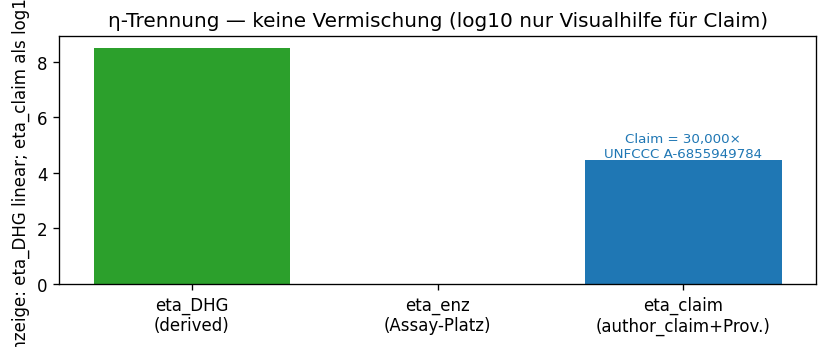

In [35]:
eta_rows = [
    ("eta_DHG", STATE["eta_dhg"], "derived", "aus DHG/TPF abgeleitet (~8,5)", "nicht mit eta_enz / eta_claim mischen"),
    ("eta_enz", "— (Assay-Platz)", "measured", "Enzymassay-Register", "nicht mit eta_DHG / claim mischen"),
    ("eta_claim", f'{int(STATE["eta_claim"]):,}'.replace(",", ".") + "×", "author_claim",
     "30.000× Kohlenstoff-Umsetzung per Enzymen; Provenienz a/b/c; ITC/UNFCCC " + STATE["itc_id"],
     "Learner nur mit Herkunftsklasse; Claim ≠ Messung"),
]
df_eta = pd.DataFrame(eta_rows, columns=["η", "Wert", "Klasse", "Provenienz", "Regel"])
display(df_eta)

fig, ax = plt.subplots(figsize=(7, 3), dpi=120)
labels = ["eta_DHG\n(derived)", "eta_enz\n(Assay-Platz)", "eta_claim\n(author_claim+Prov.)"]
vals = [STATE["eta_dhg"], 0.0, np.log10(STATE["eta_claim"])]  # claim nur log10 zur Visualisierung
colors = ["#2ca02c", "#bbbbbb", "#1f77b4"]
bars = ax.bar(labels, vals, color=colors)
ax.set_ylabel("Anzeige: eta_DHG linear; eta_claim als log10(×)")
ax.set_title("η-Trennung — keine Vermischung (log10 nur Visualhilfe für Claim)")
ax.text(2, vals[2]+0.1, f'Claim = {int(STATE["eta_claim"]):,}×\nUNFCCC {STATE["itc_id"]}',
        ha="center", fontsize=8, color="#1f77b4")
fig.tight_layout()
fig.savefig(OUT_DIR / "dashboard_eta.png", bbox_inches="tight")
plt.show()

## 4 · ESG-Kennzahlen (Modul 04)
Governance-Telemetrie: **E** Carbon 0,9399 · **S** Social 0,9150 · **G**/Aggregat 0,9375.  
Quelle: Modul 04 / Essay §3.3, §4.5 — operational definiert, keine biologische Messung.

,Kennzahl,Score,Klasse,Provenienz
0,E · Carbon,0.9399,governance_telemetry,Modul 04 / Essay
1,S · Social,0.9150,governance_telemetry,Modul 04 / Essay
2,G · Aggregate,0.9375,governance_telemetry,Modul 04 / Essay
3,Vertical Thesis,0.9500,governance_telemetry,Modul 04 / Essay
4,Application 2,0.9450,governance_telemetry,Modul 04 / Essay


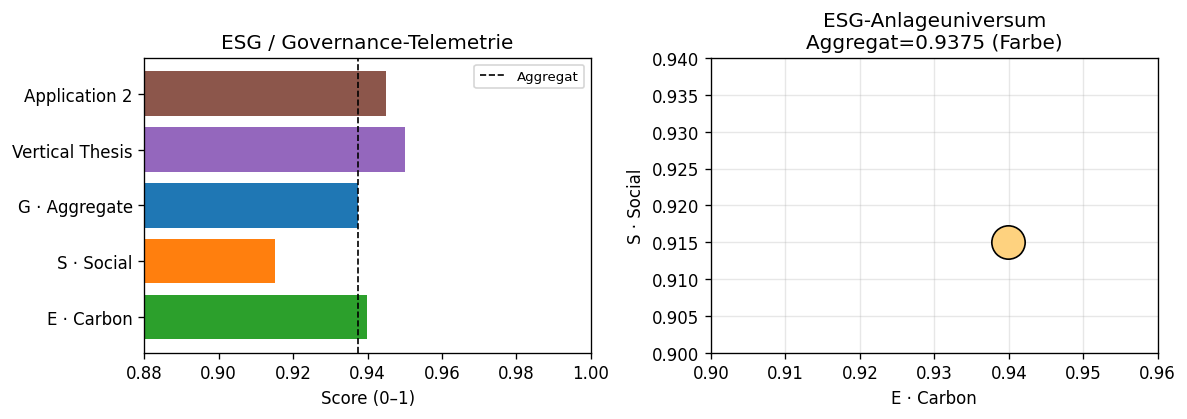

In [36]:
esg = {
    "E · Carbon": STATE["esg_carbon"],
    "S · Social": STATE["social"],
    "G · Aggregate": STATE["stability"],
    "Vertical Thesis": STATE["vertical"],
    "Application 2": STATE["app2"],
}
df_esg = pd.DataFrame({"Kennzahl": list(esg.keys()), "Score": list(esg.values()),
                       "Klasse": ["governance_telemetry"]*5,
                       "Provenienz": ["Modul 04 / Essay"]*5})
display(df_esg)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), dpi=120)
ax = axes[0]
names = list(esg.keys()); vals = list(esg.values())
ax.barh(names, vals, color=["#2ca02c", "#ff7f0e", "#1f77b4", "#9467bd", "#8c564b"])
ax.set_xlim(0.88, 1.0); ax.axvline(STATE["stability"], color="k", ls="--", lw=1, label="Aggregat")
ax.set_xlabel("Score (0–1)"); ax.set_title("ESG / Governance-Telemetrie")
ax.legend(fontsize=8)

# 3D-ish radar / ternary-like scatter E-S-G
ax = axes[1]
ax.scatter([STATE["esg_carbon"]], [STATE["social"]], s=400, c=[STATE["stability"]],
           cmap="RdYlGn", vmin=0.9, vmax=1.0, edgecolors="k", zorder=3)
ax.set_xlabel("E · Carbon"); ax.set_ylabel("S · Social")
ax.set_xlim(0.90, 0.96); ax.set_ylim(0.90, 0.94)
ax.set_title(f"ESG-Anlageuniversum\nAggregat={STATE['stability']:.4f} (Farbe)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "dashboard_esg.png", bbox_inches="tight")
plt.show()

## 5 · Q-Hebel-Modellkurve (fester Seed)
Formel der Engine-Seite (Essay Abb. 5):  
`exp(0.5·y) · (30·200) · (0.62·200) · (1500·y/200) · DHG_Faktor`  
vs. lineare Referenz `y`. **Kennzeichnung: Modellkurve / Simulation** — kein Feldmesswert. DHG-Faktor hier mit **festem Seed** (statt unseeded `Math.random`).

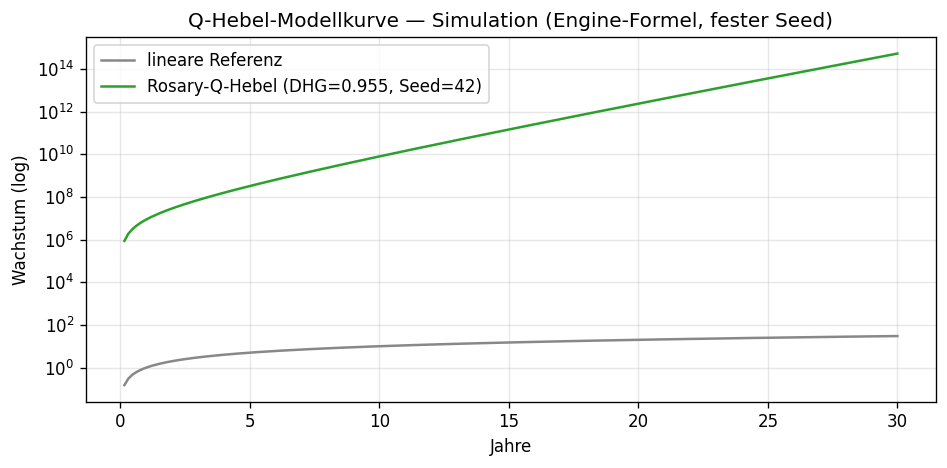

DHG-Faktor (Seed 42): 0.9548 | Wert bei Jahr≈20: 2.413e+12
Provenienz: engine.html / Essay Abb. 5 · Klasse: simulation


In [37]:
years = np.linspace(0, 30, 200)
efficiency_mechanical = 1.0
growth_tech = efficiency_mechanical * years
q_nebel = 30.0 * 200
charcoal = 0.62 * 200
# fester Seed statt Math.random 0.8–1.0
dhg_factor = float(RNG.uniform(0.8, 1.0))
growth_rosary = np.exp(years * 0.5) * q_nebel * charcoal * (1500 * years / 200) * dhg_factor
# y=0 → 0; vermeiden von log(0)
growth_rosary = np.where(years == 0, np.nan, growth_rosary)

STATE["q_hebel_dhg_factor"] = dhg_factor
STATE["q_hebel_year20"] = float(growth_rosary[np.argmin(np.abs(years - 20))])

fig, ax = plt.subplots(figsize=(8, 4), dpi=120)
ax.semilogy(years, np.where(growth_tech > 0, growth_tech, np.nan), label="lineare Referenz", color="#888")
ax.semilogy(years, growth_rosary, label=f"Rosary-Q-Hebel (DHG={dhg_factor:.3f}, Seed={SEED})", color="#2ca02c")
ax.set_xlabel("Jahre"); ax.set_ylabel("Wachstum (log)")
ax.set_title("Q-Hebel-Modellkurve — Simulation (Engine-Formel, fester Seed)")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "dashboard_qhebel.png", bbox_inches="tight")
plt.show()
print(f"DHG-Faktor (Seed {SEED}): {dhg_factor:.4f} | Wert bei Jahr≈20: {STATE['q_hebel_year20']:.3e}")
print("Provenienz: engine.html / Essay Abb. 5 · Klasse: simulation")

## 6 · Bodenkorrelationen (Kledke 1992)
Hochsichere Paare aus Tab. 13 / Tab. 20 (Essay §4.4). Graue/unsichere Zellen bleiben draußen.

,Quelle,A,B,r,Signifikanz,Provenienz
0,Tab.13 Ende n=24,O₂-Aufnahme,DHG,0.95,hochsignifikant,Kledke 1992 · Essay §4.4 · Klasse: derived/tra...
1,Tab.13 Ende,Zellulose-Abbau,O₂-Aufnahme,0.98,hochsignifikant,Kledke 1992 · Essay §4.4 · Klasse: derived/tra...
2,Tab.13 Ende,Gesamt-C,Gesamt-N,0.98,hochsignifikant,Kledke 1992 · Essay §4.4 · Klasse: derived/tra...
3,Tab.13 Ende,C/N,NO₃-N,-0.86,signifikant negativ,Kledke 1992 · Essay §4.4 · Klasse: derived/tra...
4,Tab.20,Protease,BHK,0.92,***,Kledke 1992 · Essay §4.4 · Klasse: derived/tra...
5,Tab.20,Alk. Phosphatase,BHK,0.76,***,Kledke 1992 · Essay §4.4 · Klasse: derived/tra...
6,Tab.20,Biomasse,BHK,0.75,***,Kledke 1992 · Essay §4.4 · Klasse: derived/tra...
7,Tab.20,Alk. Phosphatase,Protease,0.74,***,Kledke 1992 · Essay §4.4 · Klasse: derived/tra...
8,Tab.20,Protease,pH,0.67,***,Kledke 1992 · Essay §4.4 · Klasse: derived/tra...
9,Tab.20,Katalase,C-Gehalt,0.66,***,Kledke 1992 · Essay §4.4 · Klasse: derived/tra...


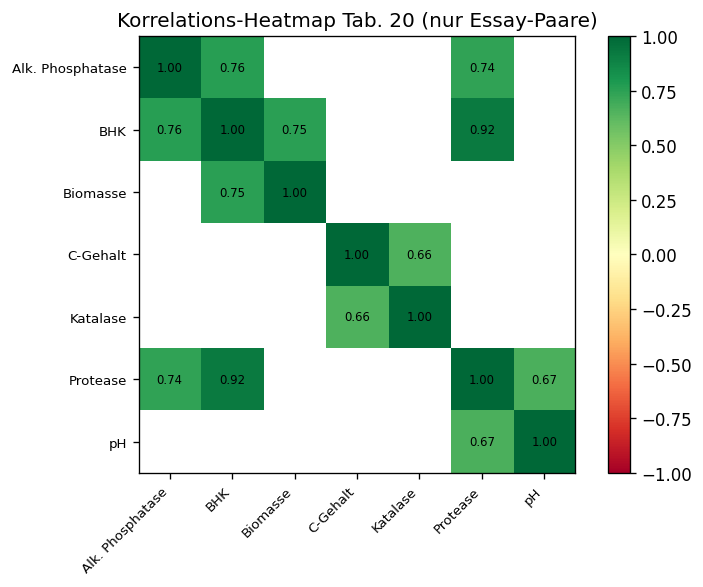

In [38]:
CORR = [
    ("Tab.13 Ende n=24", "O₂-Aufnahme", "DHG", 0.95, "hochsignifikant"),
    ("Tab.13 Ende", "Zellulose-Abbau", "O₂-Aufnahme", 0.98, "hochsignifikant"),
    ("Tab.13 Ende", "Gesamt-C", "Gesamt-N", 0.98, "hochsignifikant"),
    ("Tab.13 Ende", "C/N", "NO₃-N", -0.86, "signifikant negativ"),
    ("Tab.20", "Protease", "BHK", 0.92, "***"),
    ("Tab.20", "Alk. Phosphatase", "BHK", 0.76, "***"),
    ("Tab.20", "Biomasse", "BHK", 0.75, "***"),
    ("Tab.20", "Alk. Phosphatase", "Protease", 0.74, "***"),
    ("Tab.20", "Protease", "pH", 0.67, "***"),
    ("Tab.20", "Katalase", "C-Gehalt", 0.66, "***"),
]
df_corr = pd.DataFrame(CORR, columns=["Quelle", "A", "B", "r", "Signifikanz"])
df_corr["Provenienz"] = "Kledke 1992 · Essay §4.4 · Klasse: derived/transcribed"
display(df_corr)

# Heatmap der Tab.20-Paare (nur gelistete)
labels = sorted({*df_corr.loc[df_corr["Quelle"].str.startswith("Tab.20"), "A"],
                 *df_corr.loc[df_corr["Quelle"].str.startswith("Tab.20"), "B"]})
mat = pd.DataFrame(np.nan, index=labels, columns=labels)
for _, row in df_corr[df_corr["Quelle"].str.startswith("Tab.20")].iterrows():
    mat.loc[row["A"], row["B"]] = row["r"]
    mat.loc[row["B"], row["A"]] = row["r"]
for lab in labels:
    mat.loc[lab, lab] = 1.0

fig, ax = plt.subplots(figsize=(6.5, 5), dpi=120)
im = ax.imshow(mat.values, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = mat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Korrelations-Heatmap Tab. 20 (nur Essay-Paare)")
fig.tight_layout()
fig.savefig(OUT_DIR / "dashboard_corr.png", bbox_inches="tight")
plt.show()

## 7 · Agenda-Rosarium-Matrix (A / B / C)
Qualitative Autoreneinschätzung im Biodiversitäts-Modell Rosarium / Bio 3.0 (Essay Abb. 8).  
**Option B** = *online beworbene Beef-Snacks (Werbeanzeigen)* — keine geprüfte Shop-Identität.

,Option,Label,Health_Security,Economic_Security,Systemische_Qualität,Notiz,Klasse,Provenienz
0,A,Pommes+Burger ohne Ketchup (MAHA-Rindertalg-Fa...,2,2,1,Seed-Oil→Tallow; Symbolwechsel am POS,author_claim (qualitativ),Essay §4.6 / Abb. 8 — Punkte = qualitative Ein...
1,B,online beworbene Beef-Snacks (Werbeanzeigen),2,2,2,über Werbeanzeigen wahrgenommen; keine geprüft...,author_claim (qualitativ),Essay §4.6 / Abb. 8 — Punkte = qualitative Ein...
2,C,vegan beworbene Protein-/Superfood-Snacks,2,2,2,YouTube-Superfood-Narrative,author_claim (qualitativ),Essay §4.6 / Abb. 8 — Punkte = qualitative Ein...
3,Bio2.0,Bio 2.0 / Rosarium (Payload),5,5,5,"Morphologie, Tab.13/20, Doppelblind, HACCP, ES...",author_claim (qualitativ),Essay §4.6 / Abb. 8 — Punkte = qualitative Ein...


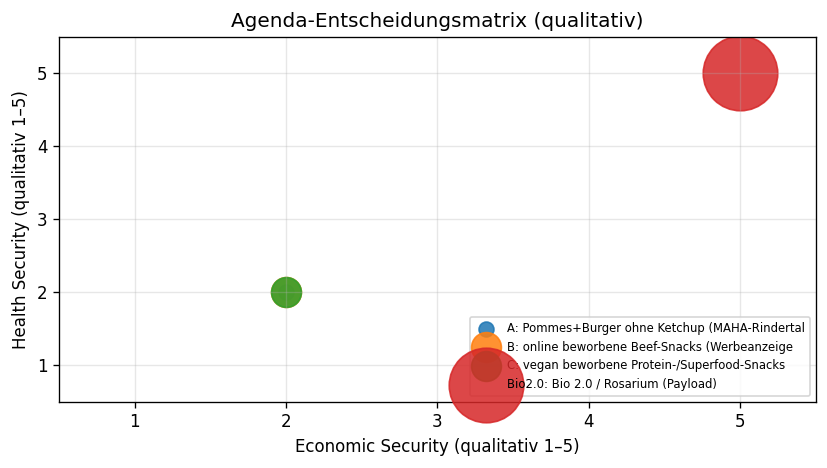

In [39]:
AGENDA = pd.DataFrame([
    {"Option": "A", "Label": "Pommes+Burger ohne Ketchup (MAHA-Rindertalg-Fast-Food)",
     "Health_Security": 2, "Economic_Security": 2, "Systemische_Qualität": 1,
     "Notiz": "Seed-Oil→Tallow; Symbolwechsel am POS"},
    {"Option": "B", "Label": "online beworbene Beef-Snacks (Werbeanzeigen)",
     "Health_Security": 2, "Economic_Security": 2, "Systemische_Qualität": 2,
     "Notiz": "über Werbeanzeigen wahrgenommen; keine geprüfte Shop-Identität"},
    {"Option": "C", "Label": "vegan beworbene Protein-/Superfood-Snacks",
     "Health_Security": 2, "Economic_Security": 2, "Systemische_Qualität": 2,
     "Notiz": "YouTube-Superfood-Narrative"},
    {"Option": "Bio2.0", "Label": "Bio 2.0 / Rosarium (Payload)",
     "Health_Security": 5, "Economic_Security": 5, "Systemische_Qualität": 5,
     "Notiz": "Morphologie, Tab.13/20, Doppelblind, HACCP, ESG; FiBL 136–145 Mrd. €"},
])
AGENDA["Klasse"] = "author_claim (qualitativ)"
AGENDA["Provenienz"] = "Essay §4.6 / Abb. 8 — Punkte = qualitative Einschätzung, keine Messwerte"
display(AGENDA)

fig, ax = plt.subplots(figsize=(7, 4), dpi=120)
for _, r in AGENDA.iterrows():
    ax.scatter(r["Economic_Security"], r["Health_Security"], s=80*r["Systemische_Qualität"]**2,
               label=f'{r["Option"]}: {r["Label"][:42]}', alpha=0.85)
ax.set_xlabel("Economic Security (qualitativ 1–5)")
ax.set_ylabel("Health Security (qualitativ 1–5)")
ax.set_xlim(0.5, 5.5); ax.set_ylim(0.5, 5.5)
ax.set_title("Agenda-Entscheidungsmatrix (qualitativ)")
ax.legend(fontsize=7, loc="lower right")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "dashboard_agenda.png", bbox_inches="tight")
plt.show()

## 8 · Sieben erkenntnistheoretische Maßgaben + ESG-Lösungen
Aus Essay §5 — jede Maßgabe steuert ein Freigabe-Gate im Entscheidungs-Panel.

In [40]:
MASSGABEN = pd.DataFrame([
    (1, "Versuchsplan-Treue & Freiheitsgrade", "G", "RCBD vs. Spaltanlage versioniert; Freigabe nur bei Passung", "rcbd_model"),
    (2, "Mehrfach verknüpfte Metriken", "E+S", "Parallele E-/S-Metriken; Abgleich Carbon 0,9399 & Social 0,9150", None),
    (3, "Doppelblind der Laborebene", "G", "SOP + Audit-Trail vor Learner-Aufnahme", "double_blind"),
    (4, "HACCP-Regelkreis", "G+E", "Kritische Grenzen; Kopplung ITC A-6855949784", "haccp"),
    (5, "Dokumentierte Metriken mit ID", "E+G", "Provenienzpflicht; Aggregation → Stabilität 0,9375", None),
    (6, "Enzyme & Morphologie gleichrangig", "E+S", "Assay-/Index-Register vor Freigabe", None),
    (7, "Mensch-in-der-Schleife", "G", "Freigabe-Gate; Modellwechsel → Governance-Eintrag", "human_gate"),
], columns=["Nr", "Maßgabe", "ESG", "Lösung", "Gate-Key"])
display(MASSGABEN)

,Nr,Maßgabe,ESG,Lösung,Gate-Key
0,1,Versuchsplan-Treue & Freiheitsgrade,G,RCBD vs. Spaltanlage versioniert; Freigabe nur...,rcbd_model
1,2,Mehrfach verknüpfte Metriken,E+S,"Parallele E-/S-Metriken; Abgleich Carbon 0,939...",None
2,3,Doppelblind der Laborebene,G,SOP + Audit-Trail vor Learner-Aufnahme,double_blind
3,4,HACCP-Regelkreis,G+E,Kritische Grenzen; Kopplung ITC A-6855949784,haccp
4,5,Dokumentierte Metriken mit ID,E+G,"Provenienzpflicht; Aggregation → Stabilität 0,...",None
5,6,Enzyme & Morphologie gleichrangig,E+S,Assay-/Index-Register vor Freigabe,None
6,7,Mensch-in-der-Schleife,G,Freigabe-Gate; Modellwechsel → Governance-Eintrag,human_gate


## 9 · Entscheidungs-Panel (transparente Formel)
**Freigabe-Score** (Governance, nicht Bio-Messung):

\[
S_{\mathrm{ESG}} = w_E\cdot E + w_S\cdot S + w_G\cdot G
\quad\text{mit}\quad w_E+w_S+w_G=1
\]

**Gates** (Maßgaben): RCBD-Treue · Doppelblind · HACCP · Mensch-in-der-Schleife · ITC-ID vorhanden · Notebook-Register geladen (Stufe 0) · AlphaFold-Archiv geladen (Stufe 1b).  
Wenn ein Gate fehlt → Status `REFINEMENT REQUIRED`, sonst `PROTOCOL LOCK` (bei \(S_{\mathrm{ESG}}\ge 0{,}90\)).

`eta_claim` und die 10.000-fache Höchst-Signifikanz bleiben **eigene Claim-Klasse** und fließen **nicht** in \(S_{\mathrm{ESG}}\) ein.  
Fehlende Notebook-Stufen (02 …) sind nur **Hinweise** und ändern \(S_{\mathrm{ESG}}\) nicht.

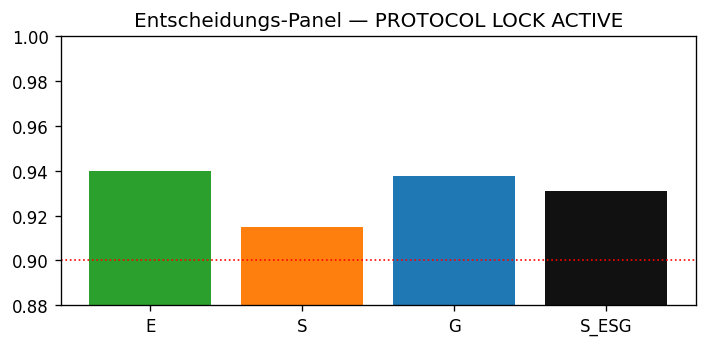

In [41]:
def decision_score(state, w_e=1/3, w_s=1/3, w_g=1/3):
    w_sum = w_e + w_s + w_g
    w_e, w_s, w_g = w_e/w_sum, w_s/w_sum, w_g/w_sum
    S = w_e*state["esg_carbon"] + w_s*state["social"] + w_g*state["stability"]
    gates = {
        "RCBD-Treue (M1)": bool(state.get("rcbd_model")),
        "Doppelblind (M3)": bool(state.get("double_blind")),
        "HACCP (M4)": bool(state.get("haccp")),
        "Mensch-in-Schleife (M7)": bool(state.get("human_gate")),
        "ITC-ID gesetzt (M5)": bool(state.get("itc_id")),
        "AlphaFold-Archiv geladen (Stufe 1b)": bool((state.get("alphafold_archive") or {}).get("loaded")),
        "Notebook-Register geladen (Stufe 0)": bool((state.get("notebook_register") or {}).get("loaded")),
    }
    all_ok = all(gates.values())
    if not all_ok:
        status = "REFINEMENT REQUIRED"
    elif S >= 0.90:
        status = "PROTOCOL LOCK ACTIVE"
    else:
        status = "REVIEW"
    return {
        "S_ESG": round(float(S), 6),
        "weights": {"w_E": w_e, "w_S": w_s, "w_G": w_g},
        "components": {"E": state["esg_carbon"], "S": state["social"], "G": state["stability"]},
        "gates": gates,
        "status": status,
        "eta_claim_separat": state["eta_claim"],
        "itc_id": state["itc_id"],
        "formel": "S_ESG = w_E*E + w_S*S + w_G*G  |  eta_claim ∉ S_ESG",
        "klasse": "governance_telemetry",
        "provenienz": "Modul 04 Scores + Essay §5 Gates",
    }

# Interaktive Gewichte (oder Defaults im Headless)
out_decision = widgets.Output() if HAS_WIDGETS else None

def render_decision(w_e=1/3, w_s=1/3, w_g=1/3, rcbd=True, dbl=True, haccp=True, human=True):
    STATE["rcbd_model"] = rcbd
    STATE["double_blind"] = dbl
    STATE["haccp"] = haccp
    STATE["human_gate"] = human
    res = decision_score(STATE, w_e, w_s, w_g)
    STATE["last_decision"] = res
    _nbreg = STATE.get("notebook_register") or {}
    _cnt = _nbreg.get("counts") or {}
    _hinw = _nbreg.get("hinweise") or []
    df_g = pd.DataFrame([(k, "OK" if v else "FEHLT") for k, v in res["gates"].items()],
                        columns=["Gate", "Status"])
    text = (
        f"**Status:** `{res['status']}`  \n"
        f"**S_ESG = {res['S_ESG']:.4f}** = "
        f"{res['weights']['w_E']:.3f}·{res['components']['E']:.4f}(E) + "
        f"{res['weights']['w_S']:.3f}·{res['components']['S']:.4f}(S) + "
        f"{res['weights']['w_G']:.3f}·{res['components']['G']:.4f}(G)  \n"
        f"eta_claim (separat, author_claim+Prov.): **{int(res['eta_claim_separat']):,}×** · ITC `{res['itc_id']}`  \n"
        f"Provenienz: {res['provenienz']}  \n"
        f"Notebook-Register: vorhanden {_cnt.get('vorhanden', '?')} · "
        f"Proxy {_cnt.get('Proxy', '?')} · fehlt {_cnt.get('fehlt', '?')} "
        f"(Hinweise: {len(_hinw)}; ∉ S_ESG)"
    )
    if HAS_WIDGETS and out_decision is not None:
        with out_decision:
            clear_output(wait=True)
            display(Markdown(text))
            display(df_g)
    else:
        print(text.replace("**", "").replace("`", ""))
        print(df_g.to_string(index=False))
    # Dashboard chart
    fig, ax = plt.subplots(figsize=(6, 3), dpi=120)
    ax.bar(["E", "S", "G", "S_ESG"], [res["components"]["E"], res["components"]["S"],
                                       res["components"]["G"], res["S_ESG"]],
           color=["#2ca02c", "#ff7f0e", "#1f77b4", "#111"])
    ax.set_ylim(0.88, 1.0); ax.set_title(f"Entscheidungs-Panel — {res['status']}")
    ax.axhline(0.90, color="red", ls=":", lw=1)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "dashboard_decision.png", bbox_inches="tight")
    if not HEADLESS:
        plt.show()
    else:
        plt.close(fig)
    return res

w_e = widgets.FloatSlider(value=1/3, min=0, max=1, step=0.01, description="w_E") if HAS_WIDGETS else None
w_s = widgets.FloatSlider(value=1/3, min=0, max=1, step=0.01, description="w_S") if HAS_WIDGETS else None
w_g = widgets.FloatSlider(value=1/3, min=0, max=1, step=0.01, description="w_G") if HAS_WIDGETS else None
g_rcbd = widgets.Checkbox(value=True, description="RCBD-Treue") if HAS_WIDGETS else None
g_dbl = widgets.Checkbox(value=True, description="Doppelblind") if HAS_WIDGETS else None
g_haccp = widgets.Checkbox(value=True, description="HACCP") if HAS_WIDGETS else None
g_human = widgets.Checkbox(value=True, description="Mensch-in-Schleife") if HAS_WIDGETS else None

def _on_change(_=None):
    render_decision(w_e.value, w_s.value, w_g.value, g_rcbd.value, g_dbl.value, g_haccp.value, g_human.value)

if HAS_WIDGETS and not HEADLESS:
    for w in (w_e, w_s, w_g, g_rcbd, g_dbl, g_haccp, g_human):
        w.observe(_on_change, names="value")
    display(widgets.VBox([widgets.HBox([w_e, w_s, w_g]),
                          widgets.HBox([g_rcbd, g_dbl, g_haccp, g_human]),
                          out_decision]))
    _on_change()
else:
    res0 = render_decision()
    print("Headless-Defaultentscheidung:", res0["status"], res0["S_ESG"])

## 10 · RKW-Cockpit (schlafend) — zuschaltbar
Gruppe **„RKW-Scouts & Kategorien (Schlaf)“** im Organigramm. Standard: **aus**.  
Existenzgründung historisch über Steinbeis/RKW Innovation begleitet — hier nur als **offline** Modul (keine Live-APIs, keine privaten Daten).

Verwandte V4-Mesh-Scouts (ebenfalls schlafend, Kontext): `MarketScout-RKW` (Marktsignale / rosary.health-Shop), `Monitoring-Scout` (Mesh-Health).  
Kopplungen an ESG-Kennzahlen, die über die dokumentierte Domain hinausgehen, sind als **Vorschlag** markiert.

In [42]:
RKW_SCOUTS = [
    {
        "code": "RKW-Innovation",
        "status": "schlafend",
        "rolle_dokumentiert": "Innovation, R&D, neue Technologien, Forschungskooperationen, RKW-spezifische Themen (Scout-Notiz).",
        "esg_feed": "Vorschlag: Innovationssignale → Q-Hebel-/Sensitivitätsbewertung und E-Metrik-Kontext (nicht gemessen).",
        "feed_tag": "Vorschlag",
    },
    {
        "code": "Uni-Campus",
        "status": "schlafend",
        "rolle_dokumentiert": "Demand-Test Uni-/Campus-Nachfrage, Präsenz Campus, Studenten-Zielgruppe; Moodle/LOGOS; rosary.center-Bildung.",
        "esg_feed": "Vorschlag: Bildungs-/Campus-Signale → Social Policy Index (S) als Kontextinput.",
        "feed_tag": "Vorschlag",
    },
    {
        "code": "Live-Learn-Earn",
        "status": "schlafend",
        "rolle_dokumentiert": "Airbnb All-Inclusive / Live-Learn-Earn / Retreat-Modelle; erlebnisorientierte Unterkünfte.",
        "esg_feed": "Vorschlag: Erlebnis-/Campus-Ökonomie → S- und G-Kontext (Mensch-in-Schleife / Angebote).",
        "feed_tag": "Vorschlag",
    },
    {
        "code": "Sales-Channels",
        "status": "schlafend",
        "rolle_dokumentiert": "Rosary.health / Shop / Vertriebskanäle; Conversion-Ideen, Plattformen, Partner.",
        "esg_feed": "Dokumentierte Domain = Shop/Kanäle (rosary.health/shop, rosary.center). Vorschlag: Marktsignale als S-/Wirtschafts-Kontext, ohne Live-API.",
        "feed_tag": "Domain dokumentiert · ESG-Kopplung Vorschlag",
    },
    {
        "code": "MicroLiving",
        "status": "schlafend",
        "rolle_dokumentiert": "Produktlinie MicroLiving / Tiny-Living / modulares Wohn- und Campus-Angebot.",
        "esg_feed": "Vorschlag: Asset-/Campus-Produktlinie → E/S-Kontext der systemischen Qualitätskette.",
        "feed_tag": "Vorschlag",
    },
]

def render_rkw(active: bool):
    STATE["rkw_on"] = bool(active)
    if not active:
        msg = "RKW-Cockpit **schlafend** (Standard). Schalter an → fünf Scout-Panels."
        if HAS_WIDGETS and out_rkw is not None:
            with out_rkw:
                clear_output(wait=True)
                display(Markdown(msg))
        else:
            print(msg.replace("**", ""))
        return
    rows = []
    for s in RKW_SCOUTS:
        rows.append({
            "Scout-Code": s["code"],
            "Status": "wach (Panel)" if active else "schlafend",
            "Rolle (dokumentiert)": s["rolle_dokumentiert"],
            "ESG-Feed": s["esg_feed"],
            "Kennzeichnung": s["feed_tag"],
        })
    df = pd.DataFrame(rows)
    note = (
        "Offline-Modul. Keine Live-APIs. Keine Agenten-Personnamen — nur Codes. "
        "Wecken im Organigramm nur über TriggerMaster/AMEISE; hier nur Anzeige."
    )
    if HAS_WIDGETS and out_rkw is not None:
        with out_rkw:
            clear_output(wait=True)
            display(Markdown("### RKW-Scouts & Kategorien — Panels"))
            display(df)
            display(Markdown(note))
            display(Markdown(
                "**Kontext V4:** `MarketScout-RKW` beobachtet Marktsignale/Shop im Lazy-Modus; "
                "`Monitoring-Scout` überwacht Mesh-Health (beide schlafend)."
            ))
    else:
        print("RKW-Cockpit AN")
        print(df.to_string(index=False))
        print(note)
    # small status fig
    fig, ax = plt.subplots(figsize=(8, 2.2), dpi=120)
    ax.barh([s["code"] for s in RKW_SCOUTS][::-1], [1]*5, color="#4caf50" if active else "#9e9e9e")
    ax.set_xlim(0, 1.2); ax.set_title("RKW-Cockpit " + ("zugeschaltet (Anzeige)" if active else "schlafend"))
    ax.set_xticks([])
    fig.tight_layout()
    fig.savefig(OUT_DIR / "dashboard_rkw.png", bbox_inches="tight")
    if not HEADLESS:
        plt.show()
    else:
        plt.close(fig)

out_rkw = widgets.Output() if HAS_WIDGETS else None
tog_rkw = widgets.ToggleButton(
    value=False,
    description="RKW-Cockpit (schlafend) zuschalten",
    button_style="",
    layout=widgets.Layout(width="360px") if HAS_WIDGETS else None,
) if HAS_WIDGETS else None

def _rkw_change(change=None):
    val = tog_rkw.value if tog_rkw is not None else False
    render_rkw(val)

if HAS_WIDGETS and not HEADLESS:
    tog_rkw.observe(_rkw_change, names="value")
    display(tog_rkw, out_rkw)
    _rkw_change()
else:
    # Headless: einmal OFF, einmal ON testen
    render_rkw(False)
    render_rkw(True)
    render_rkw(False)  # zurück auf Standard OFF
    print("RKW Headless-Test: OFF→ON→OFF ok; STATE.rkw_on=", STATE["rkw_on"])

ToggleButton(value=False, description='RKW-Cockpit (schlafend) zuschalten', layout=Layout(width='360px'))

Output()

## 11 · LLM-Assistent (optional, lokal, ohne API-Key)
Lädt **Qwen2.5-7B-Instruct** in 4-Bit (`bitsandbytes`) auf T4; bei fehlender GPU/OOM Fallback **Qwen2.5-1.5B-Instruct**.  
Apache-2.0, ungated. Das Cockpit bleibt ohne diese Zelle voll nutzbar.

Setze `SKIP_LLM=1` (Umgebung), um das Laden zu überspringen.

In [43]:
LLM = {"ready": False, "name": None, "pipe": None, "error": None}

# --- Glossar aus den echten Cockpit-Definitionen (kein freies Wissen) ---
GLOSSAR = {
    "UNFCCC": "United Nations Framework Convention on Climate Change / Klimarahmenkonvention der Vereinten Nationen. Im Cockpit nur als Provenienz der ITC-Klimafonds-Metrik (Momentum for Change Lighthouse, Reg.-Nr. A-6855949784).",
    "ITC_ID": "A-6855949784 — UNFCCC Momentum for Change Lighthouse (2016/2019/2024); Provenienzquelle (b) zu eta_claim (Kohlenstoff-Umsetzung per Enzymen).",
    "S_ESG": "Governance-Kennzahl S_ESG = w_E*E + w_S*S + w_G*G (Gewichte summiert auf 1). E=ESG Carbon Index, S=Social Policy Index, G=Aggregate Stability. Klasse: governance_telemetry (Modul 04). Keine biologische Messung.",
    "eta_Trennung": "Drei getrennte η-Begriffe: eta_DHG (derived aus DHG/TPF), eta_enz (Enzymassay-Platz), eta_claim (author_claim). Nicht vermischen.",
    "eta_claim": 'author_claim = 30.000-fache Effizienz der Kohlenstoff-Umsetzung per Enzymen. Provenienz dreifach: (a) Messungen der Diplomarbeiten — im Cockpit u.a. Kledke 1992 Tab.13 (O₂↔DHG r=0,95; Zellulose↔O₂ r=0,98; C↔N r=0,98; C/N↔NO₃ −0,86) und Tab.20 (Protease↔BHK r=0,92 ***; Alk.Phos↔BHK 0,76; Biomasse↔BHK 0,75; Protease↔pH 0,67; Katalase↔C 0,66); bereitgestellte Messwerte Tomatenerträge und DHG/TPF 153,1 mg/10 g; abgeleitetes eta_DHG≈8,5 (getrennt). (b) zertifizierter UNFCCC-/ITC-Klimafonds, Momentum for Change Lighthouse, Reg.-Nr. A-6855949784 (Registrierungen 2016/2019/2024; Brief+Siegel+Label). (c) AlphaFold-Stufe (automatisch) / Engine-Archiv: https://rosary-mom.github.io/Bio2.0/engine/ (engine/index.html) mit Mol*-Viewer UniProt P00367 (Glutamat-Dehydrogenase, afdb=P00367) und eingebettetem Notebook https://colab.research.google.com/github/Rosary-mom/7gaben-hugel/blob/main/01_AlphaFold_Protease_Test.ipynb (Spiegel: Bio2.0/notebooks/01_AlphaFold_Protease_Test.ipynb; PDB 1SCJ Boden-Protease/Subtilisin; Simulations-Schutzfaktor 0,8; in alt-Fassung Labels 1DXJ Chitinase, 3MJD Invertase). Die Zahl 30.000 steht als author_claim mit dieser Herkunftskette — nicht aus einer einzelnen Tabellenformel berechnet; fließt NICHT in S_ESG ein (eta_claim ∉ S_ESG).',
    "PROTOCOL_LOCK_ACTIVE": "Entscheidungsstatus im Panel: alle Gates OK und S_ESG >= 0.90. Bedeutet Reproduzierbarkeits-/Freigabezustand der Governance-Telemetrie — KEIN UNFCCC-Protokoll und kein Umweltbehörde-Begriff.",
    "REFINEMENT_REQUIRED": "Entscheidungsstatus: mindestens ein Gate fehlt (RCBD-Treue, Doppelblind, HACCP, Mensch-in-Schleife, ITC-ID, Notebook-Register geladen, AlphaFold-Archiv).",
    "REVIEW": "Entscheidungsstatus: Gates OK, aber S_ESG < 0.90.",
    "Evidenzleiter": "Klassen (Schema): measured, derived, simulation, governance_telemetry, author_claim, exact_formal. Keine empirische Skala.",
    "Gates": "RCBD-Treue (M1), Doppelblind (M3), HACCP (M4), Mensch-in-Schleife (M7), ITC-ID gesetzt (M5), Notebook-Register geladen (Stufe 0), AlphaFold-Archiv geladen (Stufe 1b). Fehlende Notebook-Stufen sind Hinweise und ändern S_ESG nicht.",
}

def _glossar_text():
    return "GLOSSAR (verbindlich):\n" + "\n".join(f"- {k}: {v}" for k, v in GLOSSAR.items())

def _essay_context():
    dec = STATE.get("last_decision") or decision_score(STATE)
    return f"""
Du bist der ESG-Cockpit-Assistent für EKIR/EAIR (Uwe Rosenkranz, Bio 2.0).
Antworte auf Deutsch, knapp.

HARTREGELN:
1) Verwende NUR Fakten aus diesem Kontext + GLOSSAR. Kein Weltwissen, keine erfundenen Diagramme/Behörden/Protokolle.
2) Fehlt etwas: antworte genau „Steht nicht im Cockpit.“
3) Zitiere die Cockpit-Werte, die du nutzt (E, S, G, S_ESG, Status, eta_claim, ITC-ID).
4) Vermische keine Evidenzklassen.

{_glossar_text()}

Aktueller Stand:
- E={STATE['esg_carbon']}, S={STATE['social']}, G/Aggregat={STATE['stability']}
- S_ESG={dec['S_ESG']}, Status={dec['status']}, Formel={dec['formel']}
- Gates={dec['gates']}
- eta_claim={int(STATE['eta_claim'])}× (author_claim + ITC/UNFCCC {STATE['itc_id']}) — separat von S_ESG
- RKW-Cockpit aktiv={STATE.get('rkw_on', False)}
- Q-Hebel DHG-Faktor (Seed 42)={STATE.get('q_hebel_dhg_factor')}
Option B der Agenda heißt genau: online beworbene Beef-Snacks (Werbeanzeigen).
""".strip()

def _warn_no_gpu(use_cuda: bool):
    if use_cuda:
        return
    msg = "Keine GPU! Laufzeit → Laufzeittyp ändern → T4-GPU, speichern, dann Alle ausführen. Sonst nur kleines Modell, ungenauer."
    try:
        from IPython.display import display, Markdown
        display(Markdown(f"> **⚠️ {msg}**"))
    except Exception:
        print("⚠️", msg)

def load_llm():
    if SKIP_LLM:
        LLM.update({"ready": False, "name": "STUB", "error": "SKIP_LLM=1 — Assistent übersprungen (Cockpit bleibt nutzbar)."})
        print(LLM["error"])
        return False
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
    except Exception as e:
        LLM["error"] = f"transformers/torch nicht verfügbar: {e}"
        print(LLM["error"])
        return False

    use_cuda = torch.cuda.is_available()
    _warn_no_gpu(use_cuda)
    print(f"CUDA verfügbar: {use_cuda}" + (f" | GPU: {torch.cuda.get_device_name(0)}" if use_cuda else ""))

    candidates = []
    if use_cuda:
        candidates.append(("Qwen/Qwen2.5-7B-Instruct", True))
    candidates.append(("Qwen/Qwen2.5-1.5B-Instruct", False))

    last_err = None
    for name, want_4bit in candidates:
        try:
            print(f"Lade {name} (4bit={want_4bit and use_cuda}) …")
            tok = AutoTokenizer.from_pretrained(name, trust_remote_code=True)
            kwargs = {"trust_remote_code": True}
            if want_4bit and use_cuda:
                try:
                    from transformers import BitsAndBytesConfig
                    kwargs["quantization_config"] = BitsAndBytesConfig(
                        load_in_4bit=True,
                        bnb_4bit_compute_dtype=torch.float16,
                        bnb_4bit_use_double_quant=True,
                    )
                    kwargs["device_map"] = "auto"
                except Exception as e:
                    print("bitsandbytes/4bit nicht nutzbar, Fallback:", e)
                    last_err = e
                    continue
            else:
                kwargs["dtype"] = torch.float16 if use_cuda else torch.float32
                if use_cuda:
                    kwargs["device_map"] = "auto"
            model = AutoModelForCausalLM.from_pretrained(name, **kwargs)
            gen = pipeline("text-generation", model=model, tokenizer=tok)
            LLM.update({"ready": True, "name": name, "pipe": gen, "error": None})
            print("LLM bereit:", name)
            return True
        except Exception as e:
            last_err = e
            print(f"Fehlgeschlagen {name}: {e}")
            try:
                import torch as _t
                if use_cuda:
                    _t.cuda.empty_cache()
            except Exception:
                pass
            continue
    LLM["error"] = f"Kein Modell geladen: {last_err}"
    print(LLM["error"])
    return False

def ask_cockpit(frage: str, max_new_tokens: int = 200) -> str:
    ctx = _essay_context()
    if not LLM["ready"]:
        dec = STATE.get("last_decision") or decision_score(STATE)
        return (
            f"[Stub-Assistent — kein LLM geladen: {LLM.get('error')}]\n"
            f"Frage: {frage}\n"
            f"Genutzte Werte: E={STATE['esg_carbon']}, S={STATE['social']}, "
            f"G={STATE['stability']}, S_ESG={dec['S_ESG']}, Status={dec['status']}, "
            f"eta_claim={int(STATE['eta_claim'])}× (author_claim+ITC {STATE['itc_id']}), "
            f"RKW={STATE.get('rkw_on')}.\n"
            f"Laut Glossar: S_ESG und eta_claim sind getrennt (eta_claim = 30.000× Kohlenstoff-Umsetzung per Enzymen, author_claim mit Provenienz a/b/c; eta_claim ∉ S_ESG). "
            f"PROTOCOL LOCK ACTIVE = Gates OK und S_ESG>=0.90 (Governance), kein UNFCCC-Protokoll.\n"
            f"Formel: {dec['formel']}."
        )
    messages = [
        {"role": "system", "content": ctx},
        {"role": "user", "content": frage},
    ]
    try:
        prompt = LLM["pipe"].tokenizer.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True
        )
    except Exception:
        prompt = ctx + "\n\nNutzerfrage: " + frage + "\nAssistent:"
    out = LLM["pipe"](
        prompt,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        repetition_penalty=1.1,
        return_full_text=False,
    )[0]["generated_text"]
    text = out.strip()
    if "Assistent:" in text:
        text = text.split("Assistent:")[-1].strip()
    return text

# Warnung auch hier sichtbar, bevor geladen wird
try:
    import torch as _torch_chk
    _warn_no_gpu(_torch_chk.cuda.is_available())
except Exception:
    _warn_no_gpu(False)

load_llm()

demo = ask_cockpit("Warum ist S_ESG getrennt von eta_claim, und was bedeutet PROTOCOL LOCK?")
print(demo)

if HAS_WIDGETS and not HEADLESS:
    qbox = widgets.Text(
        value="Erkläre die Agenda-Option B und den Bio-2.0-Vorsprung.",
        description="Frage:",
        layout=widgets.Layout(width="70%"),
    )
    btn = widgets.Button(description="Fragen")
    out_llm = widgets.Output()
    def _ask(_):
        with out_llm:
            clear_output(wait=True)
            print(ask_cockpit(qbox.value))
    btn.on_click(_ask)
    display(widgets.HBox([qbox, btn]), out_llm)


CUDA verfügbar: True | GPU: Tesla T4
Lade Qwen/Qwen2.5-7B-Instruct (4bit=True) …


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

LLM bereit: Qwen/Qwen2.5-7B-Instruct
S_ESG ist getrennt von eta_claim, da eta_claim speziell den author_claim repräsentiert, der eine 30.000-fache Effizienz der Kohlenstoff-Umsetzung per Enzymen ist. Dieser Wert ist separat definiert und fließt nicht in die Berechnung von S_ESG ein. 

PROTOCOL LOCK bezeichnet den Zustand, bei dem alle Gates OK sind und S_ESG ≥ 0.90. Es bedeutet, dass die Governance-Telemetrie reproduzierbar und freigegeben ist - kein UNFCCC-Protokoll oder Umweltbehörde-Begriff wird hier verwendet.


Output()

## 12 · Export Cockpit-Zustand (JSON)

In [44]:
export = {
    "projekt": "EKIR/EAIR ESG-Cockpit",
    "seed": SEED,
    "state": {k: (float(v) if isinstance(v, (np.floating,)) else v) for k, v in STATE.items() if k != "last_decision"},
    "last_decision": STATE.get("last_decision"),
    "rkw_scouts": [{"code": s["code"], "feed_tag": s["feed_tag"]} for s in RKW_SCOUTS],
    "llm": {"ready": LLM["ready"], "name": LLM["name"], "error": LLM["error"]},
}
# numpy-safe
def _jsonable(o):
    if isinstance(o, dict):
        return {k: _jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_jsonable(v) for v in o]
    if isinstance(o, (np.bool_, bool)):
        return bool(o)
    if isinstance(o, (np.floating, float)):
        return float(o)
    if isinstance(o, (np.integer, int)):
        return int(o)
    return o

path = OUT_DIR / "cockpit_state.json"
path.write_text(json.dumps(_jsonable(export), indent=2, ensure_ascii=False), encoding="utf-8")
print("geschrieben:", path)

# Composite dashboard strip for README screenshot
figs = ["dashboard_esg.png", "dashboard_qhebel.png", "dashboard_decision.png", "dashboard_corr.png"]
paths = [OUT_DIR / f for f in figs if (OUT_DIR / f).exists()]
if paths:
    from PIL import Image
    imgs = [Image.open(p).convert("RGB") for p in paths]
    # normalize heights
    h = min(im.height for im in imgs)
    imgs = [im.resize((int(im.width * h / im.height), h)) for im in imgs]
    w = sum(im.width for im in imgs)
    canvas = Image.new("RGB", (w, h), (255, 255, 255))
    x = 0
    for im in imgs:
        canvas.paste(im, (x, 0)); x += im.width
    composite = OUT_DIR / "dashboard_main.png"
    canvas.save(composite)
    print("Composite:", composite)
else:
    print("Keine Einzelcharts für Composite.")

geschrieben: /content/esg_cockpit_out/cockpit_state.json
Composite: /content/esg_cockpit_out/dashboard_main.png


---
**Hinweise**
- Öffentliche Links: https://rosary.health/shop · https://rosary.center · Pfad `k3/ESG_Cockpit.ipynb`.
- ITC-Klimafonds-Metrik: UNFCCC Momentum for Change Lighthouse, Reg.-Nr. **A-6855949784** (dokumentiert).
- Keine IBANs, keine privaten Kontakte, keine API-Keys in diesem Notebook.